# 6. How the models were trained (GPU, not re-run here)

Training needed a GPU (an H100 slice, until 2026-09-25), so this notebook does not re-run it. It shows the recipe
and the saved training logs. The re-check of every model from its file ran on a free Kaggle T4.

**The control:** every route gets exactly 3000 optimiser steps, so no route wins by being trained longer.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # run from the repository root
sys.path.insert(0, "src")
import numpy as np
from IPython.display import Image, display

## 6.1 The recipe (from `src/train_routes.py`)

```python
opt   = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=0.05)   # lr = 1e-4
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=args.steps)       # steps = 3000, batch 256
...
loss = F.cross_entropy(out, y, label_smoothing=0.1)
if teacher is not None:                                   # route D only: distillation
    loss = 0.5 * loss + 0.5 * F.kl_div(F.log_softmax(out / 2, 1),
                                       F.softmax(tl / 2, 1), reduction="batchmean") * 4.0
```

The model computes with rounded weights but learns as if the rounding were not there (quantisation-aware
training), so it adapts to the damage. The saved model is always the one at step 3000, never the best checkpoint.

## 6.2 Training curves

Accuracy on a 10,240-photo slice of the validation set, logged every 500 steps (seed 0).

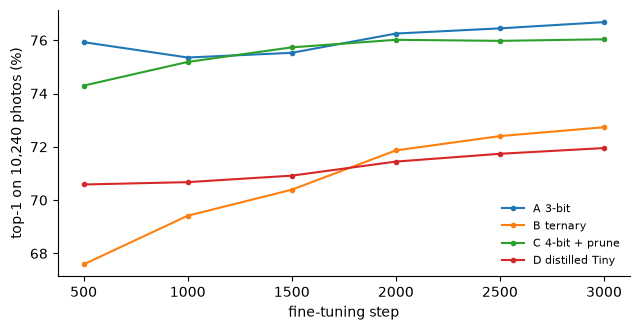

In [2]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for r, name in zip("ABCD", ["A 3-bit", "B ternary", "C 4-bit + prune", "D distilled Tiny"]):
    h = json.load(open(f"evidence/logs/train_{r}_s0.json"))["history"]
    ax.plot([x["step"] for x in h], [x["top1_subset"] for x in h], marker="o", ms=3, label=name)
ax.set_xlabel("fine-tuning step"); ax.set_ylabel("top-1 on 10,240 photos (%)"); ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

In [3]:
for r in "ABCD":
    g = []
    for s in (0, 1, 2):
        h = {x["step"]: x["top1_subset"] for x in json.load(open(f"evidence/logs/train_{r}_s{s}.json"))["history"]}
        g.append(h[3000] - h[2000])
    print(f"route {r}: gain over the last 1,000 steps = " + ", ".join(f"{v:+.2f}" for v in g))

route A: gain over the last 1,000 steps = +0.43, +0.21, +0.22
route B: gain over the last 1,000 steps = +0.87, +0.90, +1.40
route C: gain over the last 1,000 steps = +0.02, +0.23, +0.63
route D: gain over the last 1,000 steps = +0.51, +0.09, +0.29


**Reading it:** ternary was still improving fastest at the end, so the ranking belongs to this training budget.

## 6.3 The Kaggle re-check

Every model was reloaded from its file on a different GPU and scored again. 99.71% of the 600,000 per-photo
answers match the original run (the rest differ through float16 vs bfloat16 rounding).

In [4]:
R = json.load(open("evidence/rescore/rescore.json"))
changed = 0
for s in (0, 1, 2):
    old = json.load(open(f"evidence/logs/evalclean_s{s}.json"))["results"]
    for r in "ABCD":
        changed += int((np.array(old[r]["clean"]["correct"]) != np.array(R["results"][f"{r}-s{s}"]["clean"]["correct"])).sum())
print("GPU:", R["gpu"], "| per-photo answers that changed:", changed, "of 600,000 ->",
      f"{100*(1-changed/600000):.2f}% match")

GPU: Tesla T4 | per-photo answers that changed: 1728 of 600,000 -> 99.71% match
